In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("aug_train.csv")
test = pd.read_csv("aug_test.csv")

print("Train :", train.shape)
print("Test :", test.shape)

train.head()


Train : (19158, 14)
Test : (2129, 13)


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [2]:

# Informations sur les colonnes
train.info()

# Statistiques descriptives
display(train.describe(include="all"))

# Nombre de valeurs manquantes
missing = pd.DataFrame({
    "Valeurs manquantes": train.isnull().sum(),
    "Pourcentage (%)": (train.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Pourcentage (%)", ascending=False))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
count,19158.000000,19158,19158.000000,14650,19158,18772,18698,16345,19093,13220,13018,18735,19158.000000,19158.000000
unique,NaN,123,NaN,3,2,3,5,6,22,8,6,6,NaN,NaN
top,NaN,city_103,NaN,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1,NaN,NaN
freq,NaN,4355,NaN,13221,13792,13817,11598,14492,3286,3083,9817,8040,NaN,NaN
mean,16875.358179,NaN,0.828848,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.366896,0.249348
std,9616.292592,NaN,0.123362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.058462,0.432647
min,1.000000,NaN,0.448000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000
25%,8554.250000,NaN,0.740000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000,0.000000
50%,16982.500000,NaN,0.903000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.000000,0.000000
75%,25169.750000,NaN,0.920000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,88.000000,0.000000


,Valeurs manquantes,Pourcentage (%)
company_type,6140,32.05
company_size,5938,30.99
gender,4508,23.53
major_discipline,2813,14.68
education_level,460,2.40
last_new_job,423,2.21
enrolled_university,386,2.01
experience,65,0.34
enrollee_id,0,0.00
city,0,0.00


In [3]:

print("Doublons train :", train.duplicated().sum())
print("Doublons test :", test.duplicated().sum())

print("IDs dupliqués train :", train["enrollee_id"].duplicated().sum())
print("IDs dupliqués test :", test["enrollee_id"].duplicated().sum())


Doublons train : 0
Doublons test : 0
IDs dupliqués train : 0
IDs dupliqués test : 0


In [4]:

# Créer des copies pour conserver les données originales
train_clean = train.copy()
test_clean = test.copy()

# Colonnes catégorielles avec valeurs manquantes
cols_missing = [
    "gender",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "experience",
    "company_size",
    "company_type",
    "last_new_job"
]

for col in cols_missing:
    train_clean[col] = train_clean[col].fillna("Unknown")
    test_clean[col] = test_clean[col].fillna("Unknown")

print("Valeurs manquantes train :")
print(train_clean.isnull().sum())

print("Valeurs manquantes test :")
print(test_clean.isnull().sum())


Valeurs manquantes train :
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64
Valeurs manquantes test :
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
dtype: int64


In [5]:

# Conversion des années d'expérience
experience_mapping = {
    "<1": 0,
    ">20": 21,
    "Unknown": np.nan
}

# Conversion des années depuis le dernier emploi
job_mapping = {
    "never": 0,
    ">4": 5,
    "Unknown": np.nan
}

for df in [train_clean, test_clean]:
    df["experience_num"] = pd.to_numeric(
        df["experience"].replace(experience_mapping),
        errors="coerce"
    )

    df["last_new_job_num"] = pd.to_numeric(
        df["last_new_job"].replace(job_mapping),
        errors="coerce"
    )


In [6]:

for df in [train_clean, test_clean]:
    print("Dimensions :", df.shape)

    print("Valeurs manquantes :")
    print(df.isnull().sum())

    print("Doublons :", df.duplicated().sum())

    print("Heures de formation négatives :",
          (df["training_hours"] < 0).sum())

    print("Indice de développement hors [0, 1] :",
          (~df["city_development_index"].between(0, 1)).sum())

    print("---------------------")


Dimensions : (19158, 16)
Valeurs manquantes :
enrollee_id                 0
city                        0
city_development_index      0
gender                      0
relevent_experience         0
enrolled_university         0
education_level             0
major_discipline            0
experience                  0
company_size                0
company_type                0
last_new_job                0
training_hours              0
target                      0
experience_num             65
last_new_job_num          423
dtype: int64
Doublons : 0
Heures de formation négatives : 0
Indice de développement hors [0, 1] : 0
---------------------
Dimensions : (2129, 15)
Valeurs manquantes :
enrollee_id                0
city                       0
city_development_index     0
gender                     0
relevent_experience        0
enrolled_university        0
education_level            0
major_discipline           0
experience                 0
company_size               0
company_type     

In [7]:

train_clean.to_csv("train_clean.csv", index=False)
test_clean.to_csv("test_clean.csv", index=False)

print("Nettoyage terminé !")


Nettoyage terminé !


In [8]:

display(train_clean.head())

print("Nombre de lignes :", train_clean.shape[0])
print("Nombre de colonnes :", train_clean.shape[1])

print("Valeurs de target :")
print(train_clean["target"].value_counts())


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target,experience_num,last_new_job_num
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,Unknown,Unknown,1,36,1.0,21.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0,15.0,5.0
2,11561,city_21,0.624,Unknown,No relevent experience,Full time course,Graduate,STEM,5,Unknown,Unknown,never,83,0.0,5.0,0.0
3,33241,city_115,0.789,Unknown,No relevent experience,Unknown,Graduate,Business Degree,<1,Unknown,Pvt Ltd,never,52,1.0,0.0,0.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0,21.0,4.0


Nombre de lignes : 19158
Nombre de colonnes : 16
Valeurs de target :
target
0.0    14381
1.0     4777
Name: count, dtype: int64


In [9]:

# Vérification du nettoyage

print("1. Dimensions :", train_clean.shape)

print("\n2. Valeurs manquantes :")
print(train_clean.isnull().sum())

print("\n3. Doublons :", train_clean.duplicated().sum())

print("\n4. Répartition target :")
print(train_clean["target"].value_counts())

print("\n5. Valeurs Unknown :")
for col in cols_missing:
    print(col, ":", (train_clean[col] == "Unknown").sum())

print("\n6. Nombre de lignes conservées :")
print(len(train) == len(train_clean))


1. Dimensions : (19158, 16)

2. Valeurs manquantes :
enrollee_id                 0
city                        0
city_development_index      0
gender                      0
relevent_experience         0
enrolled_university         0
education_level             0
major_discipline            0
experience                  0
company_size                0
company_type                0
last_new_job                0
training_hours              0
target                      0
experience_num             65
last_new_job_num          423
dtype: int64

3. Doublons : 0

4. Répartition target :
target
0.0    14381
1.0     4777
Name: count, dtype: int64

5. Valeurs Unknown :
gender : 4508
enrolled_university : 386
education_level : 460
major_discipline : 2813
experience : 65
company_size : 5938
company_type : 6140
last_new_job : 423

6. Nombre de lignes conservées :
True


In [10]:

# Vérifier les conversions
display(
    train_clean[
        ["experience", "experience_num",
         "last_new_job", "last_new_job_num"]
    ].head(15)
)

# Vérifier que target n'a pas changé
print(
    "Target inchangée :",
    train_clean["target"].equals(train["target"])
)

# Vérifier que les IDs n'ont pas changé
print(
    "IDs inchangés :",
    train_clean["enrollee_id"].equals(train["enrollee_id"])
)


,experience,experience_num,last_new_job,last_new_job_num
0,>20,21.0,1,1.0
1,15,15.0,>4,5.0
2,5,5.0,never,0.0
3,<1,0.0,never,0.0
4,>20,21.0,4,4.0
5,11,11.0,1,1.0
6,5,5.0,1,1.0
7,13,13.0,>4,5.0
8,7,7.0,1,1.0
9,17,17.0,>4,5.0


Target inchangée : True
IDs inchangés : True


In [11]:

# Vérifier les valeurs manquantes restantes

print("Valeurs manquantes dans TRAIN :")
print(train_clean.isnull().sum())

print("\nValeurs manquantes dans TEST :")
print(test_clean.isnull().sum())


Valeurs manquantes dans TRAIN :
enrollee_id                 0
city                        0
city_development_index      0
gender                      0
relevent_experience         0
enrolled_university         0
education_level             0
major_discipline            0
experience                  0
company_size                0
company_type                0
last_new_job                0
training_hours              0
target                      0
experience_num             65
last_new_job_num          423
dtype: int64

Valeurs manquantes dans TEST :
enrollee_id                0
city                       0
city_development_index     0
gender                     0
relevent_experience        0
enrolled_university        0
education_level            0
major_discipline           0
experience                 0
company_size               0
company_type               0
last_new_job               0
training_hours             0
experience_num             5
last_new_job_num          40
dtype: i

In [12]:

cols_num = ["experience_num", "last_new_job_num"]

for col in cols_num:
    mediane = train_clean[col].median()
    train_clean[col] = train_clean[col].fillna(mediane)
    test_clean[col] = test_clean[col].fillna(mediane)

print("Valeurs manquantes train :",
      train_clean.isnull().sum().sum())

print("Valeurs manquantes test :",
      test_clean.isnull().sum().sum())


Valeurs manquantes train : 0
Valeurs manquantes test : 0


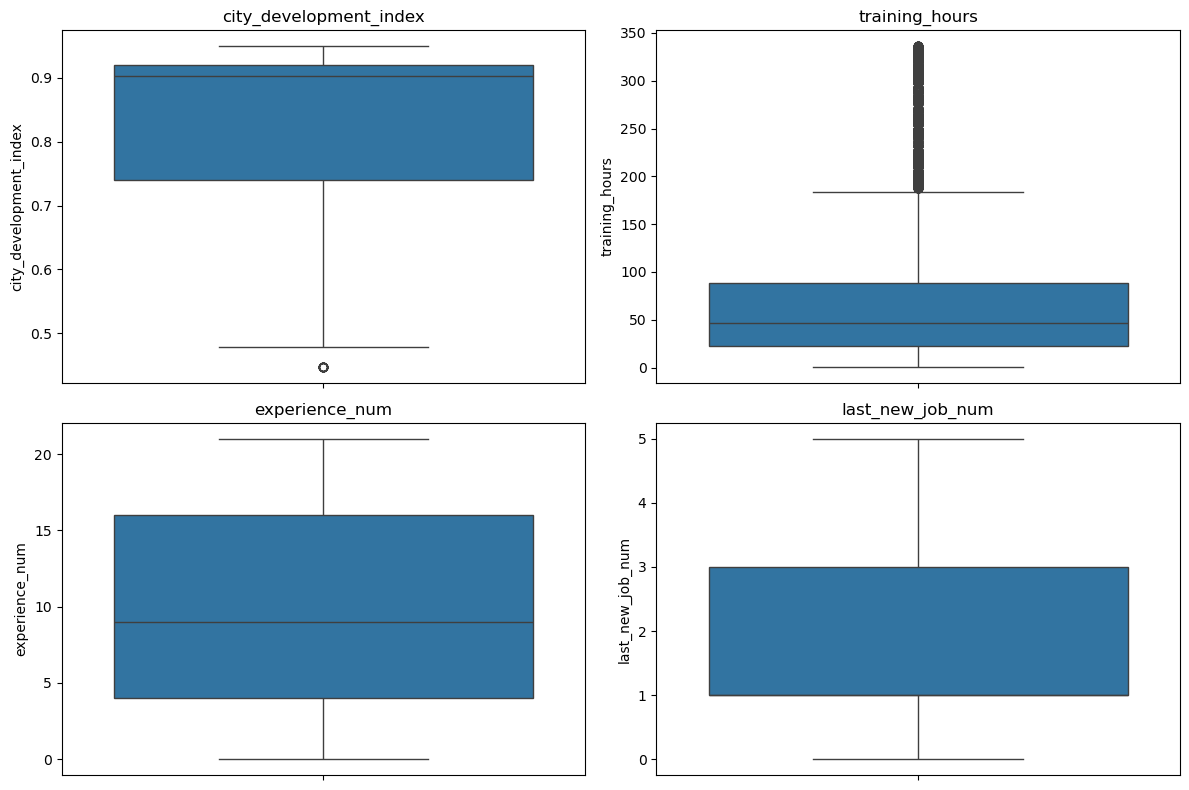

In [13]:

# Visualisation des valeurs aberrantes

import matplotlib.pyplot as plt
import seaborn as sns

colonnes = [
    "city_development_index",
    "training_hours",
    "experience_num",
    "last_new_job_num"
]

plt.figure(figsize=(12, 8))

for i, col in enumerate(colonnes, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=train_clean[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [14]:

# Vérifier les valeurs minimales et maximales

colonnes = [
    "city_development_index",
    "training_hours",
    "experience_num",
    "last_new_job_num"
]

display(
    train_clean[colonnes].describe()
)


,city_development_index,training_hours,experience_num,last_new_job_num
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,0.828848,65.366896,10.096409,1.978338
std,0.123362,60.058462,6.765820,1.663502
min,0.448000,1.000000,0.000000,0.000000
25%,0.740000,23.000000,4.000000,1.000000
50%,0.903000,47.000000,9.000000,1.000000
75%,0.920000,88.000000,16.000000,3.000000
max,0.949000,336.000000,21.000000,5.000000


In [15]:

for col in colonnes:
    Q1 = train_clean[col].quantile(0.25)
    Q3 = train_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    outliers = train_clean[
        (train_clean[col] < limite_inf) |
        (train_clean[col] > limite_sup)
    ]

    print(col, ":", len(outliers), "outliers")


city_development_index : 17 outliers
training_hours : 984 outliers
experience_num : 0 outliers
last_new_job_num : 0 outliers


In [16]:

# Vérification finale du Data Cleaning

for nom, df in [("TRAIN", train_clean), ("TEST", test_clean)]:
    print(f"\n===== {nom} =====")
    print("Lignes :", df.shape[0])
    print("Colonnes :", df.shape[1])
    print("Valeurs manquantes :", df.isnull().sum().sum())
    print("Doublons :", df.duplicated().sum())
    print("IDs dupliqués :", df["enrollee_id"].duplicated().sum())

    print("Training hours valides :",
          df["training_hours"].between(0, 336).all())

    print("City index valide :",
          df["city_development_index"].between(0, 1).all())



===== TRAIN =====
Lignes : 19158
Colonnes : 16
Valeurs manquantes : 0
Doublons : 0
IDs dupliqués : 0
Training hours valides : True
City index valide : True

===== TEST =====
Lignes : 2129
Colonnes : 15
Valeurs manquantes : 0
Doublons : 0
IDs dupliqués : 0
Training hours valides : True
City index valide : True


In [17]:

train_clean.to_csv("aug_train_clean.csv", index=False)
test_clean.to_csv("aug_test_clean.csv", index=False)

print("Datasets nettoyés et enregistrés !")


Datasets nettoyés et enregistrés !


In [18]:

# Vérification des catégories

for col in train_clean.select_dtypes(include="object").columns:
    print(f"\n{col} :")
    print(train_clean[col].value_counts(dropna=False))



city :
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
            ... 
city_111       3
city_129       3
city_121       3
city_140       1
city_171       1
Name: count, Length: 123, dtype: int64

gender :
gender
Male       13221
Unknown     4508
Female      1238
Other        191
Name: count, dtype: int64

relevent_experience :
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

enrolled_university :
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
Unknown               386
Name: count, dtype: int64

education_level :
education_level
Graduate          11598
Masters            4361
High School        2017
Unknown             460
Phd                 414
Primary School      308
Name: count, dtype: int64

major_discipline :
major_discipline
STEM               14492
Unknown             2813
Humanities           669
Other                381


In [19]:

# Vérification finale des catégories

for nom, df in [("TRAIN", train_clean), ("TEST", test_clean)]:
    print(f"\n===== {nom} =====")

    for col in df.select_dtypes(include="object").columns:
        valeurs = df[col].dropna()

        espaces = (valeurs != valeurs.str.strip()).sum()

        print(
            f"{col} : {df[col].nunique()} catégories, "
            f"{espaces} valeurs avec espaces inutiles"
        )



===== TRAIN =====
city : 123 catégories, 0 valeurs avec espaces inutiles
gender : 4 catégories, 0 valeurs avec espaces inutiles
relevent_experience : 2 catégories, 0 valeurs avec espaces inutiles
enrolled_university : 4 catégories, 0 valeurs avec espaces inutiles
education_level : 6 catégories, 0 valeurs avec espaces inutiles
major_discipline : 7 catégories, 0 valeurs avec espaces inutiles
experience : 23 catégories, 0 valeurs avec espaces inutiles
company_size : 9 catégories, 0 valeurs avec espaces inutiles
company_type : 7 catégories, 0 valeurs avec espaces inutiles
last_new_job : 7 catégories, 0 valeurs avec espaces inutiles

===== TEST =====
city : 108 catégories, 0 valeurs avec espaces inutiles
gender : 4 catégories, 0 valeurs avec espaces inutiles
relevent_experience : 2 catégories, 0 valeurs avec espaces inutiles
enrolled_university : 4 catégories, 0 valeurs avec espaces inutiles
education_level : 6 catégories, 0 valeurs avec espaces inutiles
major_discipline : 7 catégories, 0 

In [20]:

# Sauvegarde finale des datasets nettoyés

train_clean.to_csv("aug_train_clean.csv", index=False)
test_clean.to_csv("aug_test_clean.csv", index=False)

print("Data Cleaning terminé avec succès !")


Data Cleaning terminé avec succès !


In [21]:

# Vérifier la cohérence des colonnes TRAIN / TEST

colonnes_train = set(train_clean.columns) - {"target"}
colonnes_test = set(test_clean.columns)

print("Colonnes identiques :", colonnes_train == colonnes_test)

# Vérifier que les identifiants ne se répètent pas
ids_communs = set(train_clean["enrollee_id"]) & set(test_clean["enrollee_id"])

print("IDs communs :", len(ids_communs))

# Vérifier les valeurs de la cible
print("Valeurs target :", sorted(train_clean["target"].unique()))


Colonnes identiques : True
IDs communs : 0
Valeurs target : [np.float64(0.0), np.float64(1.0)]


In [22]:

print("TRAIN avant nettoyage :", train.shape[0])
print("TRAIN après nettoyage :", train_clean.shape[0])

print("TEST avant nettoyage :", test.shape[0])
print("TEST après nettoyage :", test_clean.shape[0])

print("Valeurs Unknown dans company_type :",
      (train_clean["company_type"] == "Unknown").sum())

print("Valeurs Unknown dans company_size :",
      (train_clean["company_size"] == "Unknown").sum())


TRAIN avant nettoyage : 19158
TRAIN après nettoyage : 19158
TEST avant nettoyage : 2129
TEST après nettoyage : 2129
Valeurs Unknown dans company_type : 6140
Valeurs Unknown dans company_size : 5938


In [24]:

from nettoyage_rh_modulaire import charger_donnees, verifier_doublons

train, test = charger_donnees()

verifier_doublons(train)


{'lignes_dupliquees': 0, 'ids_dupliques': 0}

In [25]:

from nettoyage_rh_modulaire import traiter_valeurs_manquantes_categorielles

# Nettoyage des colonnes catégorielles
train_clean = traiter_valeurs_manquantes_categorielles(train)
test_clean = traiter_valeurs_manquantes_categorielles(test)

# Vérifier les valeurs manquantes restantes
print("TRAIN :")
print(train_clean.isnull().sum())

print("\nTEST :")
print(test_clean.isnull().sum())


TRAIN :
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64

TEST :
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
dtype: int64


In [26]:

import nettoyage_rh_modulaire as nettoyage

train, test = nettoyage.charger_donnees()

print("TRAIN :", train.shape)
print("TEST :", test.shape)


TRAIN : (19158, 14)
TEST : (2129, 13)


In [27]:

print("TRAIN :", nettoyage.verifier_doublons(train))
print("TEST :", nettoyage.verifier_doublons(test))


TRAIN : {'lignes_dupliquees': 0, 'ids_dupliques': 0}
TEST : {'lignes_dupliquees': 0, 'ids_dupliques': 0}


In [28]:

train_clean = nettoyage.traiter_valeurs_manquantes_categorielles(train)
test_clean = nettoyage.traiter_valeurs_manquantes_categorielles(test)

print("Valeurs manquantes TRAIN :")
print(train_clean.isnull().sum())

print("\nValeurs manquantes TEST :")
print(test_clean.isnull().sum())


Valeurs manquantes TRAIN :
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64

Valeurs manquantes TEST :
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
dtype: int64


In [29]:

train_clean = nettoyage.convertir_variables(train_clean)
test_clean = nettoyage.convertir_variables(test_clean)

display(train_clean[
    ["experience", "experience_num",
     "last_new_job", "last_new_job_num"]
].head(10))


,experience,experience_num,last_new_job,last_new_job_num
0,>20,21.0,1,1.0
1,15,15.0,>4,5.0
2,5,5.0,never,0.0
3,<1,0.0,never,0.0
4,>20,21.0,4,4.0
5,11,11.0,1,1.0
6,5,5.0,1,1.0
7,13,13.0,>4,5.0
8,7,7.0,1,1.0
9,17,17.0,>4,5.0


In [30]:

medianes = nettoyage.calculer_medianes(train_clean)

train_clean = nettoyage.traiter_valeurs_manquantes_numeriques(
    train_clean, medianes
)

test_clean = nettoyage.traiter_valeurs_manquantes_numeriques(
    test_clean, medianes
)

print("Valeurs manquantes TRAIN :",
      train_clean.isnull().sum().sum())

print("Valeurs manquantes TEST :",
      test_clean.isnull().sum().sum())


Valeurs manquantes TRAIN : 0
Valeurs manquantes TEST : 0


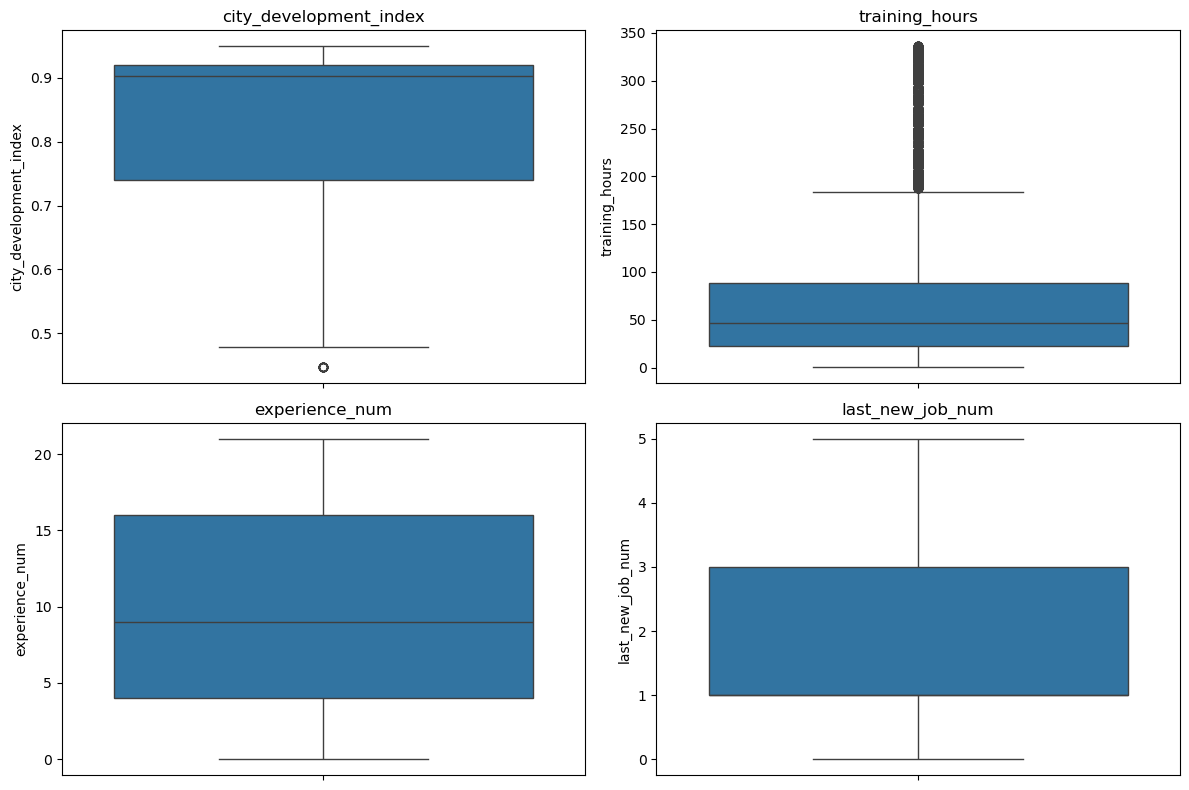

In [31]:

colonnes = [
    "city_development_index",
    "training_hours",
    "experience_num",
    "last_new_job_num"
]

# Boxplots
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, colonnes):
    sns.boxplot(y=train_clean[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


In [32]:

for col in colonnes:
    q1 = train_clean[col].quantile(0.25)
    q3 = train_clean[col].quantile(0.75)

    iqr = q3 - q1

    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    nb_outliers = (
        (train_clean[col] < limite_inf) |
        (train_clean[col] > limite_sup)
    ).sum()

    print(col, ":", nb_outliers, "outliers")


city_development_index : 17 outliers
training_hours : 984 outliers
experience_num : 0 outliers
last_new_job_num : 0 outliers


In [33]:

print("TRAIN :")
print(nettoyage.verifier_categories(train_clean))

print("\nTEST :")
print(nettoyage.verifier_categories(test_clean))


TRAIN :
                     categories  espaces_inutiles
city                        123                 0
gender                        4                 0
relevent_experience           2                 0
enrolled_university           4                 0
education_level               6                 0
major_discipline              7                 0
experience                   23                 0
company_size                  9                 0
company_type                  7                 0
last_new_job                  7                 0

TEST :
                     categories  espaces_inutiles
city                        108                 0
gender                        4                 0
relevent_experience           2                 0
enrolled_university           4                 0
education_level               6                 0
major_discipline              7                 0
experience                   23                 0
company_size                  9   

In [34]:

print("===== TRAIN =====")
print(nettoyage.verifier_qualite(train_clean))

print("\n===== TEST =====")
print(nettoyage.verifier_qualite(test_clean))


===== TRAIN =====
{'lignes': 19158, 'colonnes': 16, 'valeurs_manquantes': 0, 'lignes_dupliquees': 0, 'ids_dupliques': 0, 'training_hours_positives': True, 'city_index_dans_0_1': True}

===== TEST =====
{'lignes': 2129, 'colonnes': 15, 'valeurs_manquantes': 0, 'lignes_dupliquees': 0, 'ids_dupliques': 0, 'training_hours_positives': True, 'city_index_dans_0_1': True}


In [35]:

resultat = nettoyage.verifier_coherence_train_test(
    train_clean, test_clean
)

print(resultat)


{'colonnes_identiques_hors_target': True, 'ids_communs': 0, 'target_binaire': True}


In [37]:

nettoyage.sauvegarder_donnees(
    train_clean,
    test_clean
)

print("Data Cleaning terminé avec succès !")


Data Cleaning terminé avec succès !


In [38]:

# Vérifier la situation actuelle
print(train_clean["gender"].value_counts())


gender
Male       13221
Unknown     4508
Female      1238
Other        191
Name: count, dtype: int64


In [40]:

import importlib
import nettoyage_rh_modulaire as nettoyage

importlib.reload(nettoyage)


<module 'nettoyage_rh_modulaire' from 'C:\\Users\\ASUS\\nettoyage_rh_modulaire.py'>

In [41]:

# Repartir des données originales
train_test_correction = nettoyage.traiter_valeurs_manquantes_categorielles(train)

print(train_test_correction["gender"].value_counts())

print("Valeurs manquantes :",
      train_test_correction["gender"].isnull().sum())


gender
Male             13221
Non renseigné     4508
Female            1238
Other              191
Name: count, dtype: int64
Valeurs manquantes : 0


In [42]:

print("Ancienne version :")
print(train_clean["gender"].value_counts())

print("\nNouvelle version :")
print(train_test_correction["gender"].value_counts())


Ancienne version :
gender
Male       13221
Unknown     4508
Female      1238
Other        191
Name: count, dtype: int64

Nouvelle version :
gender
Male             13221
Non renseigné     4508
Female            1238
Other              191
Name: count, dtype: int64
